# Taller: Banco de preguntas analíticas — Proyecto Academix
**CESDE · Visualización de datos** · Docente: Gustavo Montoya Escobar

Este notebook responde 15 preguntas del banco usando los datos de **Academix** (tareas y calificaciones).
Cada pregunta sigue la fórmula del taller: **pregunta → cálculo → visualización → interpretación**.

### De dónde salen los datos
Academix expone una API REST (Spring Boot). Este notebook usa dos recursos:

| Recurso | Endpoint | Columnas que usamos |
|---|---|---|
| Tareas | `GET /api/tareas` | `materiaNombre`, `tipo`, `grado`, `fecha` (fecha de entrega), `estadoActivo` |
| Calificaciones | `GET /api/calificaciones` | `materiaNombre`, `estudianteNombre`, `act1`, `act2`, `act3`, `promedio` |

Se puede trabajar de dos formas (se elige en la celda de configuración):
- **`"api"`**: lee los datos reales con el backend encendido en `http://localhost:8080`.
- **`"csv"`**: lee `datos/tareas.csv` y `datos/calificaciones.csv`, que son **datos de ejemplo** con las mismas columnas que devuelve la API (420 tareas y 320 calificaciones del año 2026).

### Adaptación importante
La entidad `Tarea` **no tiene** un campo de estado (completada / pendiente / cancelada). Por eso la pregunta 8 usa un **estado derivado**:
- **Inactiva** → `estadoActivo = false`
- **Fecha cumplida** → la fecha de entrega ya pasó
- **Por entregar** → la fecha de entrega es hoy o posterior

Tampoco se puede calcular "días entre creación y entrega" porque el DTO no devuelve `fechaCreacion`; por eso la pregunta 13 usa el **promedio de notas por materia**.

## 0. Configuración y carga de datos

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pathlib import Path

# ---------------- CONFIGURACIÓN ----------------
FUENTE  = os.environ.get("ACADEMIX_FUENTE", "api")   # "api" (con respaldo a CSV) o "csv"
URL_API = os.environ.get("ACADEMIX_API", "http://localhost:8080/api")    # backend de Academix encendido
HOY     = pd.Timestamp.today().normalize()   # fecha de corte para "por entregar"
# HOY = pd.Timestamp("2026-10-30")       # descomentar para fijar la fecha y repetir resultados
# -----------------------------------------------

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BASE = Path.cwd()                      # carpeta desde donde se ejecuta el notebook (taller_academix/)
CARPETA_DATOS = BASE / "datos"
CARPETA_GRAFICAS = BASE / "graficas"
CARPETA_GRAFICAS.mkdir(exist_ok=True)

def guardar(fig, nombre):
    """Guarda cada gráfica en la carpeta graficas/ para usarla en el informe."""
    fig.savefig(CARPETA_GRAFICAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

DIAS  = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

def etiqueta_mes(periodo):
    return f"{MESES[periodo.month - 1]} {periodo.year}"

In [2]:
def cargar_desde_api(recurso):
    respuesta = requests.get(f"{URL_API}/{recurso}", timeout=90)
    respuesta.raise_for_status()          # lanza error si la API responde 4xx o 5xx
    return pd.DataFrame(respuesta.json())

if FUENTE == "api":
    try:
        tareas = cargar_desde_api("tareas")
        calificaciones = cargar_desde_api("calificaciones")
        print("Datos cargados desde la API de Academix.")
    except Exception as error:
        print(f"No se pudo leer la API ({error}).")
        print("¿Está encendido el backend? Se usarán los CSV de ejemplo.")
        FUENTE = "csv"

if FUENTE == "csv":
    tareas = pd.read_csv(CARPETA_DATOS / "tareas.csv")
    calificaciones = pd.read_csv(CARPETA_DATOS / "calificaciones.csv")
    print("Datos cargados desde los CSV de ejemplo.")

print(f"Tareas: {tareas.shape[0]} filas x {tareas.shape[1]} columnas")
print(f"Calificaciones: {calificaciones.shape[0]} filas x {calificaciones.shape[1]} columnas")
tareas.head()

Datos cargados desde la API de Academix.
Tareas: 37 filas x 10 columnas
Calificaciones: 347 filas x 10 columnas


,id,titulo,descripcion,materiaId,materiaNombre,tipo,grado,fecha,observaciones,estadoActivo
0,1,Informe de laboratorio - Español,Informe de laboratorio - Español,2,Español,LABORATORIO,6B,2026-11-28,,True
1,2,Consulta sobre un tema - Tecnología,Consulta sobre un tema - Tecnología,9,Tecnología,INVESTIGACION,6A,2026-11-14,Traer material,True
2,3,Práctica de laboratorio - Matemáticas,Práctica de laboratorio - Matemáticas,1,Matemáticas,LABORATORIO,10B,2026-11-01,Traer material,True
3,4,Práctica de laboratorio - Español,Práctica de laboratorio - Español,2,Español,LABORATORIO,6B,2026-11-06,,True
4,5,Guía de repaso - Español,Guía de repaso - Español,2,Español,TAREA,6B,2026-11-23,,True


### Preparación: tipos correctos y columnas derivadas

In [3]:
tareas["fecha"] = pd.to_datetime(tareas["fecha"])
tareas["mes"] = tareas["fecha"].dt.to_period("M")
tareas["dia_semana"] = tareas["fecha"].dt.dayofweek.map(dict(enumerate(DIAS)))
tareas["tipo_dia"] = np.where(tareas["fecha"].dt.dayofweek >= 5, "Fin de semana", "Entre semana")

def estado_derivado(fila):
    if not fila["estadoActivo"]:
        return "Inactiva"
    if fila["fecha"] < HOY:
        return "Fecha cumplida"
    return "Por entregar"

tareas["estado"] = tareas.apply(estado_derivado, axis=1)

# Revisión de calidad
print("Valores nulos por columna:")
print(tareas[["materiaNombre", "tipo", "fecha", "estadoActivo"]].isna().sum())
print("\nRegistros duplicados:", tareas.duplicated(subset="id").sum())
print(f"Periodo analizado: {tareas['fecha'].min():%d/%m/%Y} a {tareas['fecha'].max():%d/%m/%Y}")
print(f"Fecha de corte (hoy): {HOY:%d/%m/%Y}")

# Series que se reutilizan en varias preguntas
por_mes = tareas.groupby("mes").size()
conteo_materias = tareas["materiaNombre"].value_counts()

Valores nulos por columna:
materiaNombre    0
tipo             0
fecha            0
estadoActivo     0
dtype: int64

Registros duplicados: 0
Periodo analizado: 26/10/2026 a 03/12/2026
Fecha de corte (hoy): 06/11/2026


C:\Users\Kevin\AppData\Local\Temp\ipykernel_13480\1457467901.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tareas["dia_semana"] = tareas["fecha"].dt.dayofweek.map(dict(enumerate(DIAS)))
C:\Users\Kevin\AppData\Local\Temp\ipykernel_13480\1457467901.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tareas["tipo_dia"] = np.where(tareas["fecha"].dt.dayofweek >= 5, "Fin de semana", "Entre semana")


---
# Bloque 01 · Tendencias en el tiempo

### Pregunta 1
**¿Cómo se comportó la cantidad de tareas por mes durante el año?**
Calcule el total por mes (según la fecha de entrega), represéntelo con una gráfica de líneas y explique si la tendencia es creciente, decreciente o estable.

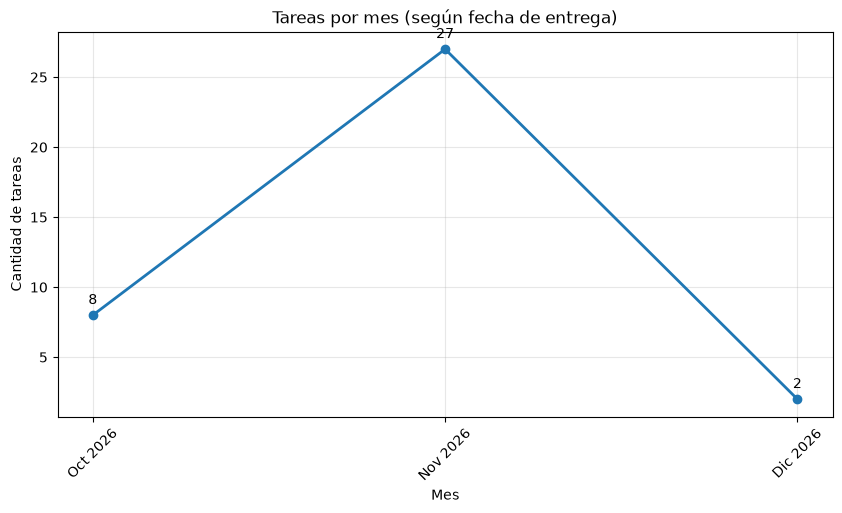

Tendencia general: decreciente (la recta ajustada cambia -3.0 tareas por mes).
Mes con más tareas: Nov 2026 (27).
Mes con menos tareas: Dic 2026 (2).


In [4]:
etiquetas = [etiqueta_mes(p) for p in por_mes.index]

fig, ax = plt.subplots()
ax.plot(etiquetas, por_mes.values, marker="o", linewidth=2)
for x, y in zip(etiquetas, por_mes.values):
    ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("Tareas por mes (según fecha de entrega)")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad de tareas")
plt.xticks(rotation=45)
guardar(fig, "p01_tareas_por_mes")
plt.show()

# Tendencia: pendiente de una recta ajustada a los datos
pendiente = np.polyfit(range(len(por_mes)), por_mes.values, 1)[0]
if pendiente > 0.5:
    tendencia = "creciente"
elif pendiente < -0.5:
    tendencia = "decreciente"
else:
    tendencia = "estable"

print(f"Tendencia general: {tendencia} (la recta ajustada cambia {pendiente:+.1f} tareas por mes).")
print(f"Mes con más tareas: {etiqueta_mes(por_mes.idxmax())} ({por_mes.max()}).")
print(f"Mes con menos tareas: {etiqueta_mes(por_mes.idxmin())} ({por_mes.min()}).")

**Interpretación:** la línea no es plana: hay meses de mucha carga y meses de poca. El resultado impreso indica si, en conjunto, la tendencia es creciente, decreciente o estable. Lo que los datos **no** dicen es la causa de los picos (por ejemplo, vacaciones o cierre de periodo); eso habría que confirmarlo con el calendario académico.

### Pregunta 2
**¿Qué días de la semana tienen más fechas de entrega?**
Calcule el total por día, represéntelo con barras ordenadas y explique qué días concentran la actividad.

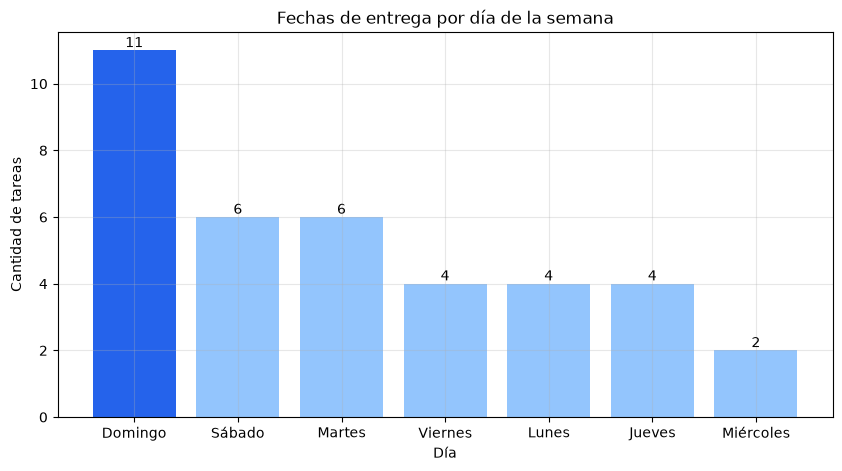

Los días con más entregas son Domingo (11) y Sábado (6),
que juntos suman el 45.9 % de todas las entregas.


In [5]:
por_dia = tareas["dia_semana"].value_counts().reindex(DIAS, fill_value=0).sort_values(ascending=False)

fig, ax = plt.subplots()
colores = ["#2563eb" if i == 0 else "#93c5fd" for i in range(len(por_dia))]
barras = ax.bar(por_dia.index, por_dia.values, color=colores)
ax.bar_label(barras)
ax.set_title("Fechas de entrega por día de la semana")
ax.set_xlabel("Día")
ax.set_ylabel("Cantidad de tareas")
guardar(fig, "p02_entregas_por_dia")
plt.show()

top2 = por_dia.head(2)
porc_top2 = top2.sum() / por_dia.sum() * 100
print(f"Los días con más entregas son {top2.index[0]} ({top2.iloc[0]}) y {top2.index[1]} ({top2.iloc[1]}),")
print(f"que juntos suman el {porc_top2:.1f} % de todas las entregas.")

### Pregunta 3
**¿Las tareas del último mes aumentaron o disminuyeron frente al mes anterior?**
Calcule ambos valores, la variación porcentual y represente la comparación con barras.

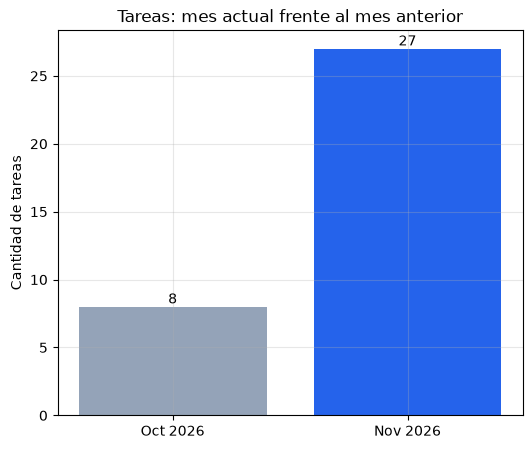

Oct 2026: 8 tareas · Nov 2026: 27 tareas
Las tareas aumentaron: variación de +237.5 %.


In [6]:
mes_actual = HOY.to_period("M")
mes_anterior = mes_actual - 1

valor_actual = por_mes.get(mes_actual, 0)
valor_anterior = por_mes.get(mes_anterior, 0)

fig, ax = plt.subplots(figsize=(6, 5))
barras = ax.bar([etiqueta_mes(mes_anterior), etiqueta_mes(mes_actual)],
                [valor_anterior, valor_actual], color=["#94a3b8", "#2563eb"])
ax.bar_label(barras)
ax.set_title("Tareas: mes actual frente al mes anterior")
ax.set_ylabel("Cantidad de tareas")
guardar(fig, "p03_mes_actual_vs_anterior")
plt.show()

if valor_anterior > 0:
    variacion = (valor_actual - valor_anterior) / valor_anterior * 100
    sentido = "aumentaron" if variacion > 0 else "disminuyeron" if variacion < 0 else "se mantuvieron"
    print(f"{etiqueta_mes(mes_anterior)}: {valor_anterior} tareas · {etiqueta_mes(mes_actual)}: {valor_actual} tareas")
    print(f"Las tareas {sentido}: variación de {variacion:+.1f} %.")
else:
    print("El mes anterior no tiene tareas, no se puede calcular la variación porcentual.")

---
# Bloque 02 · Participación y composición

### Pregunta 7
**¿Cuál es la participación de cada materia dentro del total de tareas?**
Calcule el porcentaje, construya una gráfica de dona y explique qué materias dominan.

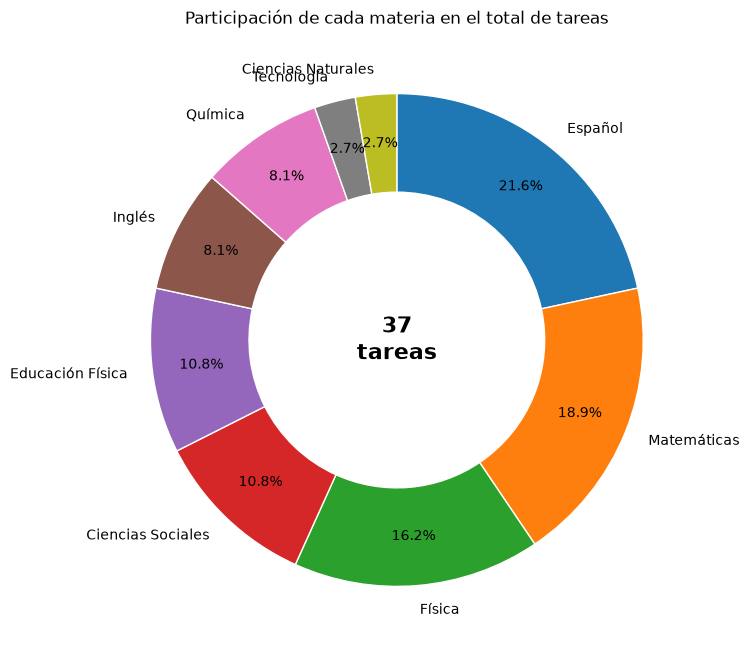

materiaNombre
Español               21.6
Matemáticas           18.9
Física                16.2
Ciencias Sociales     10.8
Educación Física      10.8
Inglés                 8.1
Química                8.1
Tecnología             2.7
Ciencias Naturales     2.7

Las tres materias principales (Español, Matemáticas, Física) concentran el 56.8 % de las tareas.


In [7]:
participacion = conteo_materias / conteo_materias.sum() * 100

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(conteo_materias.values, labels=conteo_materias.index, autopct="%1.1f%%",
       startangle=90, counterclock=False, pctdistance=0.8,
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.text(0, 0, f"{conteo_materias.sum()}\ntareas", ha="center", va="center", fontsize=16, weight="bold")
ax.set_title("Participación de cada materia en el total de tareas")
guardar(fig, "p07_participacion_materias")
plt.show()

print(participacion.round(1).to_string())
top3_porc = participacion.head(3).sum()
print(f"\nLas tres materias principales ({', '.join(participacion.head(3).index)}) concentran el {top3_porc:.1f} % de las tareas.")

### Pregunta 8
**¿Qué porcentaje de las tareas está por entregar, con fecha cumplida o inactiva?**
Calcule la participación por estado (estado derivado, ver nota inicial), represéntela con una dona e identifique el predominante.

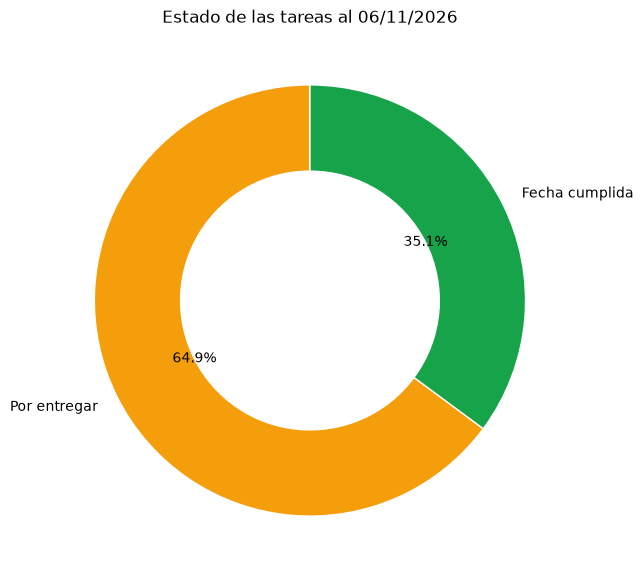

                Cantidad  Porcentaje
estado                              
Por entregar          24        64.9
Fecha cumplida        13        35.1

Estado predominante: Por entregar (64.9 %).


In [8]:
por_estado = tareas["estado"].value_counts()
colores_estado = {"Fecha cumplida": "#16a34a", "Por entregar": "#f59e0b", "Inactiva": "#9ca3af"}

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(por_estado.values, labels=por_estado.index, autopct="%1.1f%%", startangle=90,
       colors=[colores_estado[e] for e in por_estado.index],
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.set_title(f"Estado de las tareas al {HOY:%d/%m/%Y}")
guardar(fig, "p08_estado_tareas")
plt.show()

porc_estado = (por_estado / por_estado.sum() * 100).round(1)
print(pd.DataFrame({"Cantidad": por_estado, "Porcentaje": porc_estado}))
print(f"\nEstado predominante: {por_estado.idxmax()} ({porc_estado.max()} %).")

**Interpretación:** "Fecha cumplida" significa que la fecha de entrega ya pasó, **no** que el estudiante haya entregado; Academix todavía no registra entregas. Si el equipo quiere medir cumplimiento real, una mejora sería agregar a `Tarea` un enum `EstadoTarea` (PENDIENTE, ENTREGADA, CANCELADA).

---
# Bloque 03 · Promedios

### Pregunta 13
**¿Cuál es la nota promedio por materia?**
Calcule el promedio de la columna `promedio` de calificaciones para cada materia, represéntelo con barras y explique qué materias superan el promedio general.

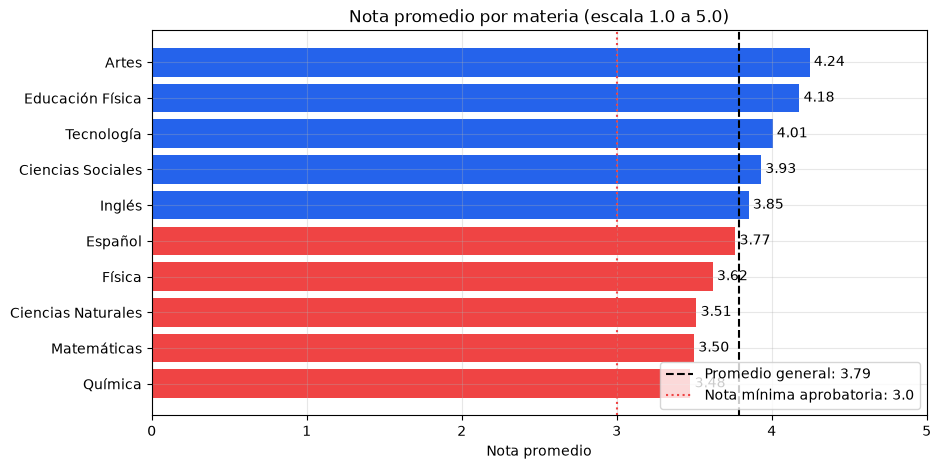

Promedio general: 3.79
Superan el promedio general: Artes, Educación Física, Tecnología, Ciencias Sociales, Inglés
Están por debajo: Química, Matemáticas, Ciencias Naturales, Física, Español


In [9]:
promedio_materia = calificaciones.groupby("materiaNombre")["promedio"].mean().sort_values()
promedio_general = calificaciones["promedio"].mean()

fig, ax = plt.subplots()
colores = ["#2563eb" if v >= promedio_general else "#ef4444" for v in promedio_materia.values]
barras = ax.barh(promedio_materia.index, promedio_materia.values, color=colores)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.axvline(promedio_general, color="black", linestyle="--", label=f"Promedio general: {promedio_general:.2f}")
ax.axvline(3.0, color="#ef4444", linestyle=":", label="Nota mínima aprobatoria: 3.0")
ax.set_xlim(0, 5)
ax.set_title("Nota promedio por materia (escala 1.0 a 5.0)")
ax.set_xlabel("Nota promedio")
ax.legend(loc="lower right")
guardar(fig, "p13_nota_promedio_materia")
plt.show()

encima = promedio_materia[promedio_materia >= promedio_general]
debajo = promedio_materia[promedio_materia < promedio_general]
print(f"Promedio general: {promedio_general:.2f}")
print("Superan el promedio general:", ", ".join(encima.index[::-1]))
print("Están por debajo:", ", ".join(debajo.index))

---
# Bloque 04 · Máximos, mínimos y rankings

### Pregunta 18
**¿Cuáles son las 5 materias con más tareas?**
Seleccione el top 5 con `nlargest()`, represéntelo con barras horizontales y explique la diferencia entre los primeros lugares.

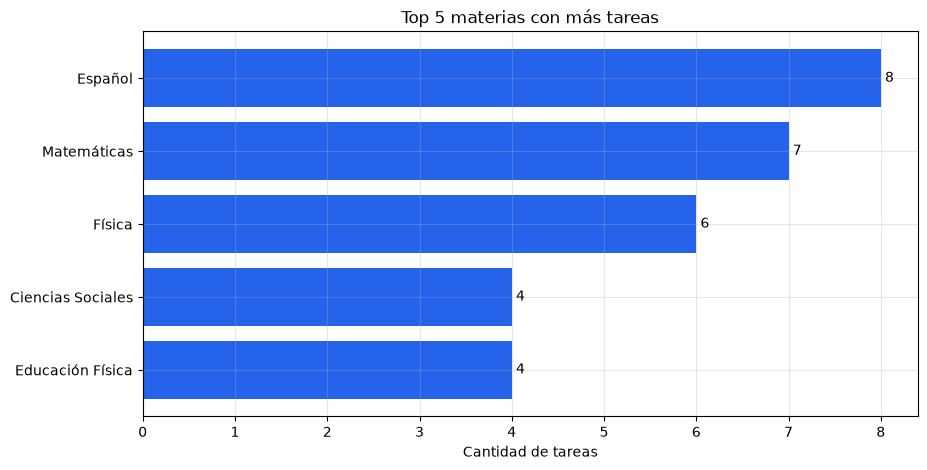

1.° Español con 8 tareas; 2.° Matemáticas con 7.
Diferencia entre los dos primeros: 1 tareas (14.3 % más).


In [10]:
top5 = conteo_materias.nlargest(5)

fig, ax = plt.subplots()
barras = ax.barh(top5.index[::-1], top5.values[::-1], color="#2563eb")
ax.bar_label(barras, padding=3)
ax.set_title("Top 5 materias con más tareas")
ax.set_xlabel("Cantidad de tareas")
guardar(fig, "p18_top5_materias")
plt.show()

dif = top5.iloc[0] - top5.iloc[1]
print(f"1.° {top5.index[0]} con {top5.iloc[0]} tareas; 2.° {top5.index[1]} con {top5.iloc[1]}.")
print(f"Diferencia entre los dos primeros: {dif} tareas ({dif / top5.iloc[1] * 100:.1f} % más).")

### Pregunta 19
**¿Cuáles son las 3 materias con menos tareas?**
Seleccione los valores más bajos con `nsmallest()` y proponga una pregunta para investigar el resultado.

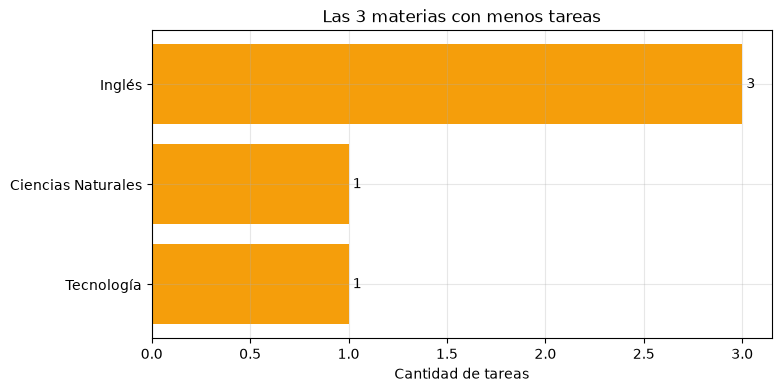

materiaNombre
Tecnología            1
Ciencias Naturales    1
Inglés                3

Pregunta para investigar: ¿Tecnología tiene menos tareas porque su evaluación es
práctica en clase (y no se registra como tarea) o porque tiene menos horas semanales?


In [11]:
bottom3 = conteo_materias.nsmallest(3)

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(bottom3.index, bottom3.values, color="#f59e0b")
ax.bar_label(barras, padding=3)
ax.set_title("Las 3 materias con menos tareas")
ax.set_xlabel("Cantidad de tareas")
guardar(fig, "p19_bottom3_materias")
plt.show()

print(bottom3.to_string())
print(f"\nPregunta para investigar: ¿{bottom3.index[0]} tiene menos tareas porque su evaluación es")
print("práctica en clase (y no se registra como tarea) o porque tiene menos horas semanales?")

### Pregunta 20
**¿Cuál fue el mes con más tareas y cuál el de menos?**
Identifique ambos extremos y explique la diferencia.

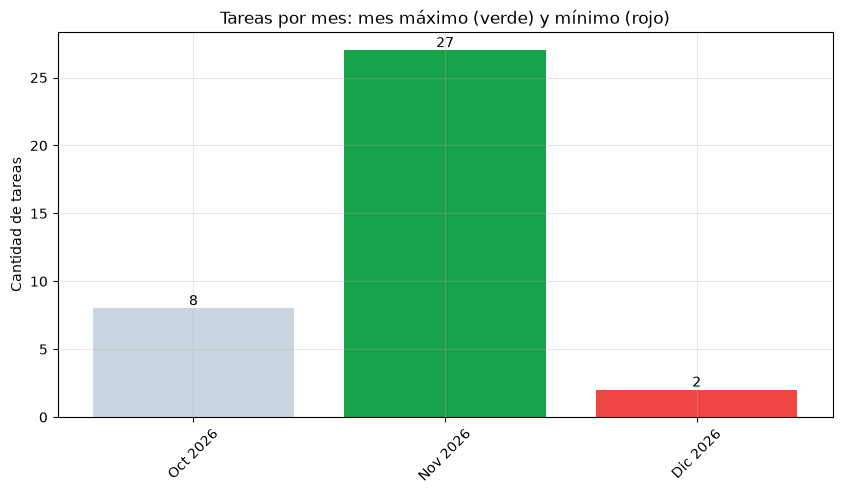

Mes con más tareas: Nov 2026 (27)
Mes con menos tareas: Dic 2026 (2)
Diferencia: 25 tareas; el mes máximo tiene 13.5 veces más.
Promedio mensual: 12.3 tareas.


In [12]:
mes_max, mes_min = por_mes.idxmax(), por_mes.idxmin()

fig, ax = plt.subplots()
colores = ["#16a34a" if m == mes_max else "#ef4444" if m == mes_min else "#cbd5e1" for m in por_mes.index]
barras = ax.bar([etiqueta_mes(m) for m in por_mes.index], por_mes.values, color=colores)
ax.bar_label(barras)
ax.set_title("Tareas por mes: mes máximo (verde) y mínimo (rojo)")
ax.set_ylabel("Cantidad de tareas")
plt.xticks(rotation=45)
guardar(fig, "p20_mes_max_min")
plt.show()

print(f"Mes con más tareas: {etiqueta_mes(mes_max)} ({por_mes.max()})")
print(f"Mes con menos tareas: {etiqueta_mes(mes_min)} ({por_mes.min()})")
print(f"Diferencia: {por_mes.max() - por_mes.min()} tareas; el mes máximo tiene {por_mes.max() / por_mes.min():.1f} veces más.")
print(f"Promedio mensual: {por_mes.mean():.1f} tareas.")

**Interpretación:** la brecha entre extremos es grande. Antes de concluir algo, conviene revisar si el mes mínimo coincide con vacaciones o si es un mes incompleto (por ejemplo, el último mes del año con pocas tareas programadas todavía).

---
# Bloque 08 · Comparaciones

### Pregunta 39
**¿Cómo se comparan las entregas entre semana frente al fin de semana?**
Clasifique las fechas, calcule el total y el promedio por día de cada grupo, y explique la diferencia.

C:\Users\Kevin\AppData\Local\Temp\ipykernel_13480\1767896192.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dias_tipo = pd.Series(np.where(calendario.dayofweek >= 5, "Fin de semana", "Entre semana")).value_counts()


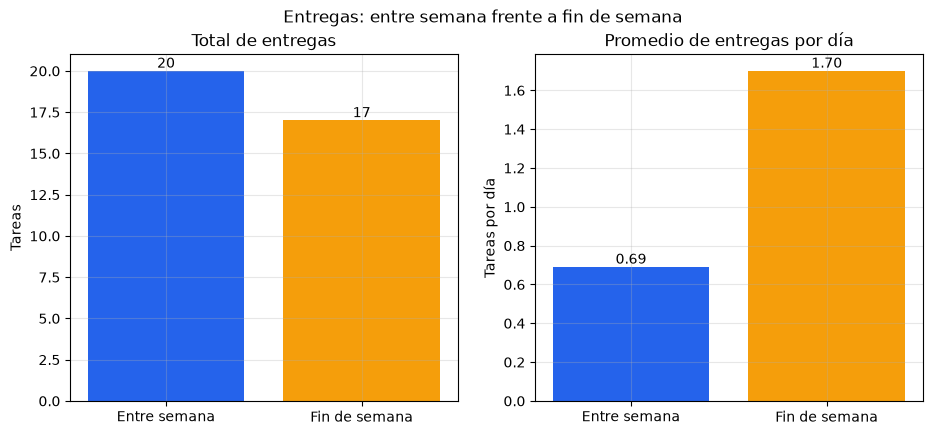

               Total  Días en el periodo  Promedio por día
Entre semana      20                  29              0.69
Fin de semana     17                  10              1.70

El 45.9 % de las tareas tiene fecha de entrega en fin de semana.


In [13]:
total_tipo = tareas["tipo_dia"].value_counts().reindex(["Entre semana", "Fin de semana"], fill_value=0)

# Promedio: tareas divididas entre la cantidad de días calendario de cada tipo en el periodo
calendario = pd.date_range(tareas["fecha"].min(), tareas["fecha"].max())
dias_tipo = pd.Series(np.where(calendario.dayofweek >= 5, "Fin de semana", "Entre semana")).value_counts()
promedio_tipo = (total_tipo / dias_tipo).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
b1 = ax1.bar(total_tipo.index, total_tipo.values, color=["#2563eb", "#f59e0b"])
ax1.bar_label(b1)
ax1.set_title("Total de entregas")
ax1.set_ylabel("Tareas")
b2 = ax2.bar(promedio_tipo.index, promedio_tipo.values, color=["#2563eb", "#f59e0b"])
ax2.bar_label(b2, fmt="%.2f")
ax2.set_title("Promedio de entregas por día")
ax2.set_ylabel("Tareas por día")
fig.suptitle("Entregas: entre semana frente a fin de semana")
guardar(fig, "p39_semana_vs_finde")
plt.show()

print(pd.DataFrame({"Total": total_tipo, "Días en el periodo": dias_tipo, "Promedio por día": promedio_tipo}))
porc_finde = total_tipo["Fin de semana"] / total_tipo.sum() * 100
print(f"\nEl {porc_finde:.1f} % de las tareas tiene fecha de entrega en fin de semana.")

**Interpretación:** comparar solo totales sería injusto, porque hay 5 días entre semana y 2 de fin de semana; por eso se calcula el promedio por día. Si aparecen entregas en sábado o domingo, el equipo podría preguntarse si la plataforma debería advertir al docente cuando elige una fecha de fin de semana.

### Pregunta 40
**¿Cómo evolucionan en el tiempo las 3 materias con más tareas?**
Seleccione las tres materias principales, construya una línea para cada una y compare sus tendencias.

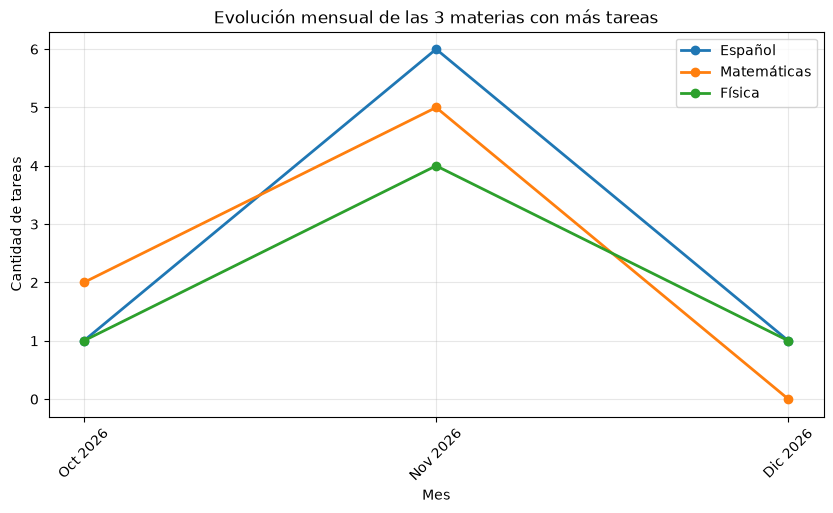

Español: pico en Nov 2026 (6 tareas), promedio 2.7 por mes.
Matemáticas: pico en Nov 2026 (5 tareas), promedio 2.3 por mes.
Física: pico en Nov 2026 (4 tareas), promedio 2.0 por mes.


In [14]:
top3_materias = conteo_materias.nlargest(3).index

evolucion = (tareas[tareas["materiaNombre"].isin(top3_materias)]
             .groupby(["mes", "materiaNombre"]).size()
             .unstack(fill_value=0)
             .reindex(por_mes.index, fill_value=0))

fig, ax = plt.subplots()
for materia in top3_materias:
    ax.plot([etiqueta_mes(m) for m in evolucion.index], evolucion[materia], marker="o", linewidth=2, label=materia)
ax.set_title("Evolución mensual de las 3 materias con más tareas")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad de tareas")
ax.legend()
plt.xticks(rotation=45)
guardar(fig, "p40_evolucion_top3")
plt.show()

for materia in top3_materias:
    serie = evolucion[materia]
    print(f"{materia}: pico en {etiqueta_mes(serie.idxmax())} ({serie.max()} tareas), promedio {serie.mean():.1f} por mes.")

---
# Bloque 09 · Preguntas para un reporte final

### Pregunta 44
**¿Cuál es la situación general de Academix en el periodo analizado?**
KPI: total de tareas, tareas por entregar, nota promedio general y materia principal, acompañados de dos gráficas y una conclusión.

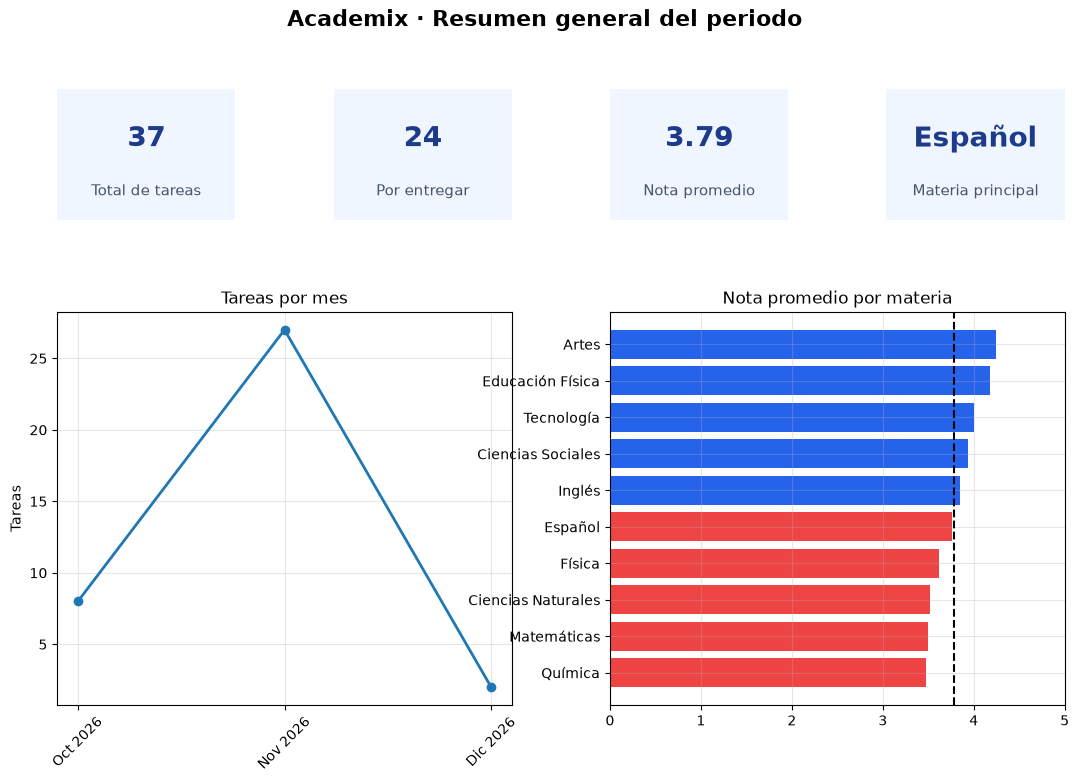

Conclusión: en el periodo se registraron 37 tareas, 24 siguen por entregar.
Español es la materia con más tareas (8, 21.6 % del total)
y la nota promedio general es 3.79; la materia con nota más baja es Química (3.48).


In [15]:
kpi_total = len(tareas)
kpi_por_entregar = (tareas["estado"] == "Por entregar").sum()
kpi_nota = promedio_general
kpi_materia = conteo_materias.idxmax()

fig = plt.figure(figsize=(13, 8))
grilla = fig.add_gridspec(2, 4, height_ratios=[1, 3], hspace=0.35, wspace=0.55)

kpis = [("Total de tareas", f"{kpi_total}"),
        ("Por entregar", f"{kpi_por_entregar}"),
        ("Nota promedio", f"{kpi_nota:.2f}"),
        ("Materia principal", kpi_materia)]
for i, (titulo, valor) in enumerate(kpis):
    ax = fig.add_subplot(grilla[0, i])
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color="#eff6ff", transform=ax.transAxes))
    ax.text(0.5, 0.62, valor, ha="center", va="center", fontsize=20 if len(valor) < 9 else 15,
            weight="bold", color="#1e3a8a")
    ax.text(0.5, 0.22, titulo, ha="center", va="center", fontsize=11, color="#475569")

ax_linea = fig.add_subplot(grilla[1, :2])
ax_linea.plot([etiqueta_mes(m) for m in por_mes.index], por_mes.values, marker="o", linewidth=2)
ax_linea.set_title("Tareas por mes")
ax_linea.set_ylabel("Tareas")
ax_linea.tick_params(axis="x", rotation=45)

ax_barras = fig.add_subplot(grilla[1, 2:])
ax_barras.barh(promedio_materia.index, promedio_materia.values,
               color=["#2563eb" if v >= promedio_general else "#ef4444" for v in promedio_materia.values])
ax_barras.axvline(promedio_general, color="black", linestyle="--")
ax_barras.set_xlim(0, 5)
ax_barras.set_title("Nota promedio por materia")

fig.suptitle("Academix · Resumen general del periodo", fontsize=16, weight="bold")
guardar(fig, "p44_reporte_kpi")
plt.show()

print(f"Conclusión: en el periodo se registraron {kpi_total} tareas, {kpi_por_entregar} siguen por entregar.")
print(f"{kpi_materia} es la materia con más tareas ({conteo_materias.max()}, {participacion.max():.1f} % del total)")
print(f"y la nota promedio general es {kpi_nota:.2f}; la materia con nota más baja es {promedio_materia.idxmin()} ({promedio_materia.min():.2f}).")

### Pregunta 45
**¿Qué tres hallazgos deberían conocer los responsables de Academix?**
Cada hallazgo tiene evidencia numérica, una visualización y una recomendación.

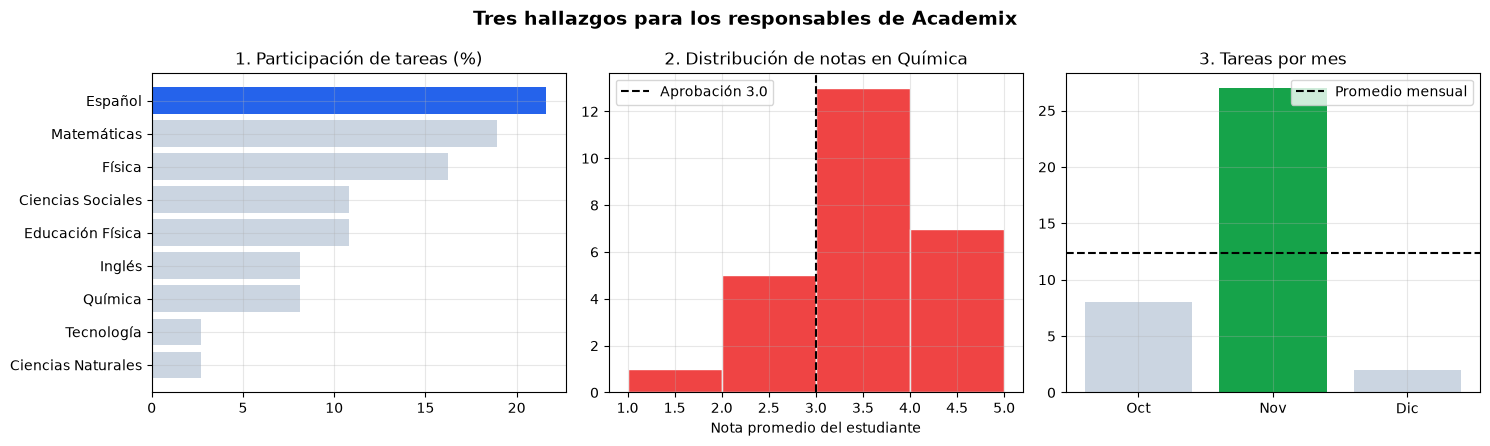

HALLAZGO 1
  Hecho: Español concentra el 21.6 % de todas las tareas.
  Recomendación: revisar con el docente si esa carga es necesaria o si puede distribuirse mejor.

HALLAZGO 2
  Hecho: Química tiene la nota promedio más baja (3.48) y el 23.1 % de los estudiantes está por debajo de 3.0.
  Recomendación: programar actividades de refuerzo y hacer seguimiento con los acudientes.

HALLAZGO 3
  Hecho: Nov 2026 tuvo 27 tareas, un 119 % más que el promedio mensual.
  Recomendación: coordinar entre docentes un calendario de entregas para evitar meses sobrecargados.


In [16]:
# Hallazgo 1: concentración de tareas
h1_materia, h1_porc = participacion.idxmax(), participacion.max()
# Hallazgo 2: materia con menor rendimiento
h2_materia, h2_nota = promedio_materia.idxmin(), promedio_materia.min()
porc_reprobando = (calificaciones.loc[calificaciones["materiaNombre"] == h2_materia, "promedio"] < 3.0).mean() * 100
# Hallazgo 3: mes pico frente al promedio mensual
h3_mes, h3_valor = por_mes.idxmax(), por_mes.max()
h3_exceso = (h3_valor / por_mes.mean() - 1) * 100

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

c1 = ["#2563eb" if m == h1_materia else "#cbd5e1" for m in participacion.index]
ejes[0].barh(participacion.index[::-1], participacion.values[::-1], color=c1[::-1])
ejes[0].set_title("1. Participación de tareas (%)")

notas_h2 = calificaciones.loc[calificaciones["materiaNombre"] == h2_materia, "promedio"]
ejes[1].hist(notas_h2, bins=range(1, 6), edgecolor="white", color="#ef4444")
ejes[1].axvline(3.0, color="black", linestyle="--", label="Aprobación 3.0")
ejes[1].set_title(f"2. Distribución de notas en {h2_materia}")
ejes[1].set_xlabel("Nota promedio del estudiante")
ejes[1].legend()

c3 = ["#16a34a" if m == h3_mes else "#cbd5e1" for m in por_mes.index]
ejes[2].bar([MESES[m.month - 1] for m in por_mes.index], por_mes.values, color=c3)
ejes[2].axhline(por_mes.mean(), color="black", linestyle="--", label="Promedio mensual")
ejes[2].set_title("3. Tareas por mes")
ejes[2].legend()

fig.suptitle("Tres hallazgos para los responsables de Academix", fontsize=14, weight="bold")
fig.tight_layout()
guardar(fig, "p45_tres_hallazgos")
plt.show()

print("HALLAZGO 1")
print(f"  Hecho: {h1_materia} concentra el {h1_porc:.1f} % de todas las tareas.")
print("  Recomendación: revisar con el docente si esa carga es necesaria o si puede distribuirse mejor.\n")
print("HALLAZGO 2")
print(f"  Hecho: {h2_materia} tiene la nota promedio más baja ({h2_nota:.2f}) y el {porc_reprobando:.1f} % de los estudiantes está por debajo de 3.0.")
print("  Recomendación: programar actividades de refuerzo y hacer seguimiento con los acudientes.\n")
print("HALLAZGO 3")
print(f"  Hecho: {etiqueta_mes(h3_mes)} tuvo {h3_valor} tareas, un {h3_exceso:.0f} % más que el promedio mensual.")
print("  Recomendación: coordinar entre docentes un calendario de entregas para evitar meses sobrecargados.")

### Pregunta 46
**¿Qué materia requiere mayor atención?**
Se usan tres indicadores y se comparan con el promedio de todas las materias:
1. **Total de tareas** (alerta si está por encima del promedio)
2. **Tareas por entregar** (alerta si está por encima del promedio)
3. **Nota promedio** (alerta si está por debajo del promedio)

La materia con más alertas es la que requiere atención; si hay empate, se elige la de más tareas por entregar.

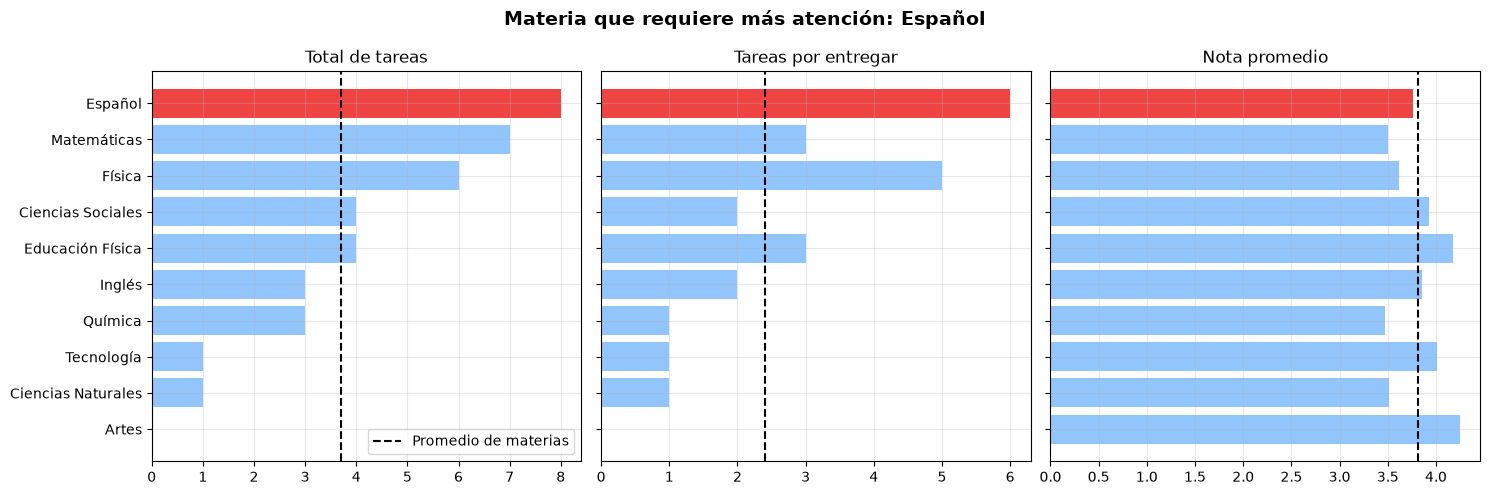

                    total_tareas  por_entregar  nota_promedio  alertas
materiaNombre                                                         
Español                      8.0           6.0           3.77        3
Física                       6.0           5.0           3.62        3
Matemáticas                  7.0           3.0           3.50        3
Educación Física             4.0           3.0           4.18        2
Ciencias Sociales            4.0           2.0           3.93        1
Ciencias Naturales           1.0           1.0           3.51        1
Química                      3.0           1.0           3.48        1
Inglés                       3.0           2.0           3.85        0
Tecnología                   1.0           1.0           4.01        0
Artes                        0.0           0.0           4.24        0

Español tiene 3 de 3 alertas:
  - 8 tareas (promedio de materias: 3.7)
  - 6 por entregar (promedio: 2.4)
  - nota promedio 3.77 (promedio: 3.81)


In [17]:
indicadores = pd.DataFrame({
    "total_tareas": conteo_materias,
    "por_entregar": tareas[tareas["estado"] == "Por entregar"].groupby("materiaNombre").size(),
    "nota_promedio": promedio_materia,
}).fillna(0)

medias = indicadores.mean()
indicadores["alertas"] = ((indicadores["total_tareas"] > medias["total_tareas"]).astype(int)
                          + (indicadores["por_entregar"] > medias["por_entregar"]).astype(int)
                          + (indicadores["nota_promedio"] < medias["nota_promedio"]).astype(int))
indicadores = indicadores.sort_values(["alertas", "por_entregar"], ascending=False)
materia_critica = indicadores.index[0]

fig, ejes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
orden = indicadores.sort_values("total_tareas").index
config = [("total_tareas", "Total de tareas"), ("por_entregar", "Tareas por entregar"), ("nota_promedio", "Nota promedio")]
for ax, (col, titulo) in zip(ejes, config):
    colores = ["#ef4444" if m == materia_critica else "#93c5fd" for m in orden]
    ax.barh(orden, indicadores.loc[orden, col], color=colores)
    ax.axvline(medias[col], color="black", linestyle="--", label="Promedio de materias")
    ax.set_title(titulo)
ejes[0].legend(loc="lower right")
fig.suptitle(f"Materia que requiere más atención: {materia_critica}", fontsize=14, weight="bold")
fig.tight_layout()
guardar(fig, "p46_materia_critica")
plt.show()

print(indicadores.round(2))
fila = indicadores.loc[materia_critica]
print(f"\n{materia_critica} tiene {int(fila['alertas'])} de 3 alertas:")
print(f"  - {int(fila['total_tareas'])} tareas (promedio de materias: {medias['total_tareas']:.1f})")
print(f"  - {int(fila['por_entregar'])} por entregar (promedio: {medias['por_entregar']:.1f})")
print(f"  - nota promedio {fila['nota_promedio']:.2f} (promedio: {medias['nota_promedio']:.2f})")

### Pregunta 47
**¿Qué decisión podría tomarse a partir de los datos?**
Se separan claramente los **hechos** (lo que muestran los números) de la **interpretación** (lo que creemos que significan).

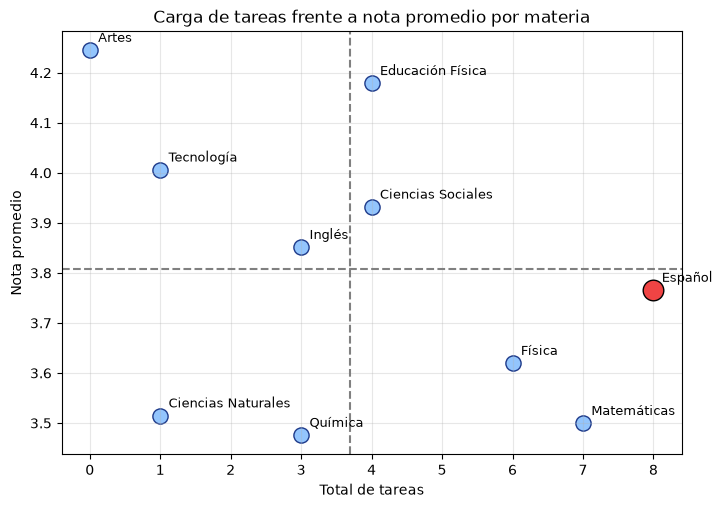

PREGUNTA: ¿Dónde debería enfocar la coordinación académica su apoyo el próximo periodo?

HECHOS:
  - Español tiene 8 tareas, frente a un promedio de 3.7 por materia.
  - Su nota promedio es 3.77, frente a 3.81 del conjunto de materias.
  - Tiene 6 tareas por entregar a partir del 06/11/2026.

INTERPRETACIÓN (no comprobada con estos datos):
  - Más tareas no se está traduciendo en mejores notas; puede que la carga no sea el problema
    o que las tareas no estén enfocadas en lo que se evalúa. La gráfica muestra asociación, no causa.

DECISIÓN PROPUESTA:
  Priorizar a Español con un plan de refuerzo y revisar con el docente el tipo de tareas,
  sin aumentar la cantidad. Medir el efecto comparando la nota promedio del siguiente periodo.


In [18]:
fila = indicadores.loc[materia_critica]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(indicadores["total_tareas"], indicadores["nota_promedio"], s=120, color="#93c5fd", edgecolor="#1e3a8a")
ax.scatter(fila["total_tareas"], fila["nota_promedio"], s=220, color="#ef4444", edgecolor="black", zorder=3)
for materia, f in indicadores.iterrows():
    ax.annotate(materia, (f["total_tareas"], f["nota_promedio"]), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.axvline(medias["total_tareas"], color="gray", linestyle="--")
ax.axhline(medias["nota_promedio"], color="gray", linestyle="--")
ax.set_title("Carga de tareas frente a nota promedio por materia")
ax.set_xlabel("Total de tareas")
ax.set_ylabel("Nota promedio")
guardar(fig, "p47_decision")
plt.show()

print("PREGUNTA: ¿Dónde debería enfocar la coordinación académica su apoyo el próximo periodo?\n")
print("HECHOS:")
print(f"  - {materia_critica} tiene {int(fila['total_tareas'])} tareas, frente a un promedio de {medias['total_tareas']:.1f} por materia.")
print(f"  - Su nota promedio es {fila['nota_promedio']:.2f}, frente a {medias['nota_promedio']:.2f} del conjunto de materias.")
print(f"  - Tiene {int(fila['por_entregar'])} tareas por entregar a partir del {HOY:%d/%m/%Y}.\n")
print("INTERPRETACIÓN (no comprobada con estos datos):")
print("  - Más tareas no se está traduciendo en mejores notas; puede que la carga no sea el problema")
print("    o que las tareas no estén enfocadas en lo que se evalúa. La gráfica muestra asociación, no causa.\n")
print("DECISIÓN PROPUESTA:")
print(f"  Priorizar a {materia_critica} con un plan de refuerzo y revisar con el docente el tipo de tareas,")
print("  sin aumentar la cantidad. Medir el efecto comparando la nota promedio del siguiente periodo.")

---
## Cierre
Todas las gráficas quedaron guardadas en la carpeta `graficas/` para usarlas en la presentación.

> *Una buena gráfica no decora: responde una pregunta. Una buena interpretación no repite los números: explica por qué son importantes.*